# A C-band radar outside the US: Anjalankoski (Finland), 30 Aug 2023

**Question.** Everything so far ran on US NEXRAD S-band data. India's network is mostly C band, in a different
file format and without HRRR or MRMS. Does the same chain work on a C-band radar from another country, with only
public data, and how close is it to rain gauges?

**Data (all open, no account).** Finnish Meteorological Institute (FMI): dual-pol C-band volumes every 5 minutes in
ODIM HDF5 (the European standard) on AWS, and hourly gauges from the FMI open-data service. 30 Aug 2023,
12-16 UTC: the wettest widespread afternoon of summer 2023 in south-east Finland.

**What changes for C band.** ODIM reader; band C settings (alpha = 0.08 dB/deg; R(A) used from 5 deg of PHIDP
span); the drop-size-adaptive alpha of notebook 05 is an S-band method and is not used; the 0 C height prior comes
from the 2 m temperature (ERA5 via Open-Meteo) because HRRR covers only the US. No MRMS: the reference is the gauges.

In [1]:
# Colab: uncomment to install
!pip install -q pysteps opencv-python-headless rasterio "git+https://github.com/manmeet3591/radarwow-pipeline" "git+https://github.com/manmeet3591/radarwow-merging"

zsh:1: command not found: pip


In [2]:
import os
import warnings

warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from radarwow.core import diagnose, fmi_aws_files, open_volume
from radarwow.merging import leave_one_out, radar_at
from radarwow.pipeline import hourly_totals
from radarwow.verify import basic_qc, fetch_fmi, gross_error_qc

FIG = "../docs/figures"
CACHE = os.path.expanduser("~/.cache/radarwow")
SITE, START, END = "fianj", "2023-08-30 12:00", "2023-08-30 16:00"
RATES = {"synthetic": "synthetic (R(A), R(KDP), R(Z))", "marshall_palmer": "Z-R Marshall-Palmer"}

## 1. What the file looks like
The health check from `radarwow.core.diagnose`, on the first volume.

In [3]:
f0 = fmi_aws_files(SITE, START, pd.Timestamp(START) + pd.Timedelta(minutes=5), cache_dir=f"{CACHE}/fmi")[0][1]
dt0 = open_volume(f0, band="C")
lat0, lon0, alt = (float(dt0[k].values) for k in ("latitude", "longitude", "altitude"))
display(Markdown(f"Radar at {lat0:.3f} N, {lon0:.3f} E, {alt:.0f} m; "
                 + ", ".join(f"{float(np.nanmedian(dt0[n].to_dataset()['elevation'].values)):.1f} deg" for n in sorted(
                     (k for k in dt0.children if k.startswith("sweep")), key=lambda s: int(s.split('_')[1])))))
display(diagnose(dt0))

Radar at 60.904 N, 27.108 E, 139 m; 0.3 deg, 0.7 deg, 1.5 deg, 3.0 deg, 5.0 deg, 9.0 deg, 2.0 deg, 7.0 deg, 11.0 deg, 15.0 deg, 25.0 deg, 45.0 deg, 0.4 deg

**None** (band C, sweep_0)

| severity | topic | finding | remedy |
|---|---|---|---|
| fix | noise | noise gates are stored, not censored (floor ~-375 dBZ at 1 km, rising 20 log r); 58% of gates are signal | qc: signal mask (SNR or noise-floor + 3 dB) before any other step |
| fix | PHIDP | system PHIDP offset ~66 deg (median of first rain gates) | kdp: subtract offset / use offset-free derivative (Vulpiani 2012) |
| info | clutter | both total (DBTH) and filtered (DBZH) reflectivity present | DBTH - DBZH = clutter power removed by the signal processor |
| info | ZDR | median ZDR in light rain +0.26 dB: no large bias |  |

## 2. Hourly totals against the gauges

In [4]:
rad = {k: hourly_totals(SITE, START, END, n_tilts=3, blockage=True, source="fmi", rate=k) for k in RATES}
g = fetch_fmi(lat0, lon0, 145, START, END, f"{CACHE}/gauges")
g["gx"] = (g["lon"] - lon0) * 111.2 * np.cos(np.deg2rad(lat0))
g["gy"] = (g["lat"] - lat0) * 111.2
x, y = rad["synthetic"]["x"].values, rad["synthetic"]["y"].values
for k in RATES:
    g[k] = np.nan
    for t, idx in g.groupby("time").groups.items():
        g.loc[idx, k] = radar_at(rad[k]["RAIN"].sel(time=t).values, x, y, g.loc[idx, "gx"].values, g.loc[idx, "gy"].values)
g = gross_error_qc(basic_qc(g, radar_col="synthetic"), radar_col="synthetic")
display(Markdown(f"{g.station.nunique()} gauges within 145 km, {len(g)} gauge-hours. Quality control: "
                 + ", ".join(f"{k}: {v}" for k, v in g["qc"].value_counts().items())))
ok = g[g.qc == "ok"]


def stats(e, r):
    m = np.isfinite(e) & np.isfinite(r)
    e, r = e[m], r[m]
    return dict(n=int(m.sum()), bias=e.sum() / r.sum(), MAE=np.mean(np.abs(e - r)), corr=np.corrcoef(e, r)[0, 1])


rows = [dict(estimate=RATES[k], **stats(ok[k].values, ok["gauge_mm"].values)) for k in RATES]
rows += [dict(estimate=f"{RATES[k]}, hour {t:%H}-{t.hour + 1:02d}", **stats(d[k].values, d["gauge_mm"].values))
         for k in ["synthetic"] for t, d in ok.groupby("time")]
display(Markdown("**Radar at the gauges** (bias = radar total / gauge total; MAE in mm)\n\n" + pd.DataFrame(rows).round(2).to_markdown(index=False)))

21 gauges within 145 km, 84 gauge-hours. Quality control: ok: 84

**Radar at the gauges** (bias = radar total / gauge total; MAE in mm)

| estimate                                   |   n |   bias |   MAE |   corr |
|:-------------------------------------------|----:|-------:|------:|-------:|
| synthetic (R(A), R(KDP), R(Z))             |  84 |   0.41 |  0.98 |   0.92 |
| Z-R Marshall-Palmer                        |  84 |   0.38 |  1.04 |   0.93 |
| synthetic (R(A), R(KDP), R(Z)), hour 12-13 |  21 |   0.57 |  0.9  |   0.96 |
| synthetic (R(A), R(KDP), R(Z)), hour 13-14 |  21 |   0.37 |  1.18 |   0.96 |
| synthetic (R(A), R(KDP), R(Z)), hour 14-15 |  21 |   0.34 |  0.98 |   0.94 |
| synthetic (R(A), R(KDP), R(Z)), hour 15-16 |  21 |   0.33 |  0.86 |   0.9  |

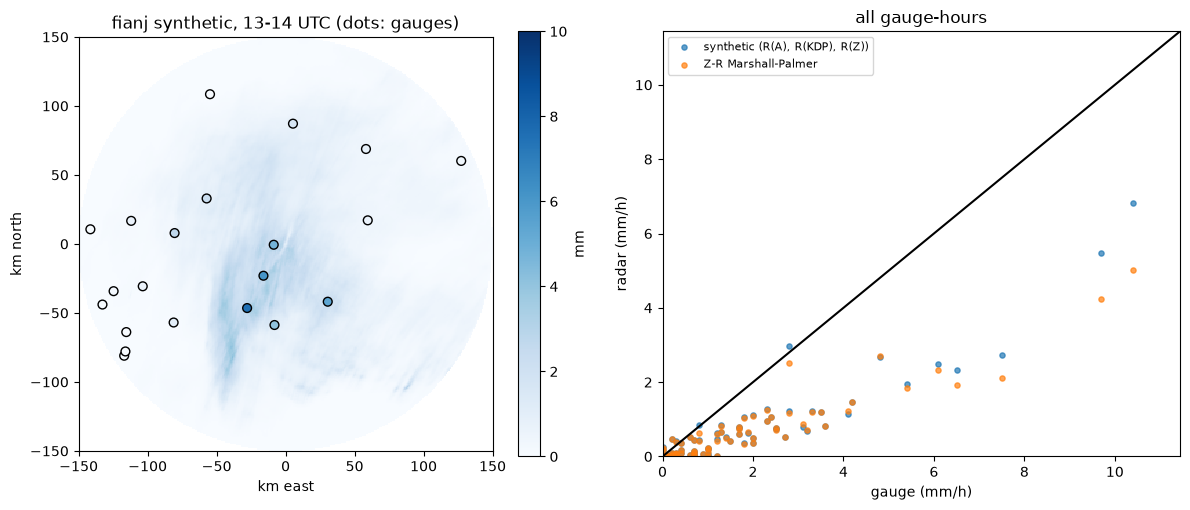

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
t = pd.Timestamp("2023-08-30 13:00")
f = rad["synthetic"]["RAIN"].sel(time=t).values
gt = ok[ok.time == t]
p = axes[0].pcolormesh(x, y, np.ma.masked_invalid(f), cmap="Blues", vmin=0, vmax=10, shading="auto")
axes[0].scatter(gt.gx, gt.gy, c=gt.gauge_mm, cmap="Blues", vmin=0, vmax=10, s=40, edgecolors="k")
axes[0].set(title=f"fianj synthetic, {t:%H}-{t.hour + 1:02d} UTC (dots: gauges)", aspect=1, xlabel="km east", ylabel="km north")
fig.colorbar(p, ax=axes[0], label="mm")
for k, c in [("synthetic", "C0"), ("marshall_palmer", "C1")]:
    axes[1].scatter(ok["gauge_mm"], ok[k], s=14, color=c, alpha=0.7, label=RATES[k])
lim = max(ok["gauge_mm"].max(), 1) * 1.1
axes[1].plot([0, lim], [0, lim], "k")
axes[1].set(xlim=(0, lim), ylim=(0, lim), xlabel="gauge (mm/h)", ylabel="radar (mm/h)", title="all gauge-hours")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(f"{FIG}/15_fianj_cband.png", dpi=100)
plt.show()

## 3. Merging with this few gauges (leave-one-out)

In [6]:
loo = []
for t, gt in ok.groupby("time"):
    field = rad["synthetic"]["RAIN"].sel(time=t).values
    for m in ["radar only", "MFB", "conditional merging", "KED"]:
        loo.append(pd.DataFrame(dict(method=m, gauge=gt["gauge_mm"].values,
                                     est=leave_one_out(m, field, x, y, gt["gx"].values, gt["gy"].values, gt["gauge_mm"].values))))
loo = pd.concat(loo)
s = pd.DataFrame([dict(method=m, **stats(d["est"].values, d["gauge"].values)) for m, d in loo.groupby("method", sort=False)])
display(Markdown("**Leave-one-out at the gauges**\n\n" + s.round(2).to_markdown(index=False)))

**Leave-one-out at the gauges**

| method              |   n |   bias |   MAE |   corr |
|:--------------------|----:|-------:|------:|-------:|
| radar only          |  84 |   0.41 |  0.98 |   0.92 |
| MFB                 |  84 |   1.02 |  0.53 |   0.94 |
| conditional merging |  84 |   1.02 |  0.54 |   0.92 |
| KED                 |  84 |   1    |  0.41 |   0.96 |

## 4. Against FMI's own product, and on a second day
FMI publishes its operational hourly radar accumulation (radar only, Z = 200 R^1.6). It is the fairest peer: if it
also falls short of the gauges, the shortfall belongs to the rain (or to radar-gauge sampling), not to our chain.
The second day, 28 Jul 2023, 08-12 UTC, was not used for any choice in this notebook.

In [7]:
from radarwow.verify import fmi_accumulation_at

rows = []
for day, (s_, e_) in {"30 Aug 2023": (START, END), "28 Jul 2023 (independent)": ("2023-07-28 08:00", "2023-07-28 12:00")}.items():
    r_ = hourly_totals(SITE, s_, e_, n_tilts=3, blockage=True, source="fmi")
    gd = fetch_fmi(lat0, lon0, 145, s_, e_, f"{CACHE}/gauges")
    gd["gx"] = (gd["lon"] - lon0) * 111.2 * np.cos(np.deg2rad(lat0))
    gd["gy"] = (gd["lat"] - lat0) * 111.2
    gd["ours"], gd["fmi"] = np.nan, np.nan
    for t_, idx in gd.groupby("time").groups.items():
        gd.loc[idx, "ours"] = radar_at(r_["RAIN"].sel(time=t_).values, r_["x"].values, r_["y"].values, gd.loc[idx, "gx"].values, gd.loc[idx, "gy"].values)
        gd.loc[idx, "fmi"] = fmi_accumulation_at(gd.loc[idx, "lat"].values, gd.loc[idx, "lon"].values, t_, f"{CACHE}/fmi_products")
    gd = gd[np.isfinite(gd.ours) & np.isfinite(gd.fmi)]
    for name in ["ours", "fmi"]:
        rows.append(dict(day=day, estimate={"ours": "radar-wow chain", "fmi": "FMI operational (radar only)"}[name], **stats(gd[name].values, gd["gauge_mm"].values)))
    ked, obs = [], []  # keep estimates and gauges in the same (grouped) order
    for t_, gt in gd.groupby("time"):
        ked += list(leave_one_out("KED", r_["RAIN"].sel(time=t_).values, r_["x"].values, r_["y"].values, gt.gx.values, gt.gy.values, gt.gauge_mm.values))
        obs += list(gt.gauge_mm.values)
    rows.append(dict(day=day, estimate="radar-wow + gauges (KED, leave-one-out)", **stats(np.array(ked), np.array(obs))))
display(Markdown("**Hourly totals at the gauges** (bias = estimate / gauge)\n\n" + pd.DataFrame(rows).round(2).to_markdown(index=False)))

**Hourly totals at the gauges** (bias = estimate / gauge)

| day                       | estimate                                |   n |   bias |   MAE |   corr |
|:--------------------------|:----------------------------------------|----:|-------:|------:|-------:|
| 30 Aug 2023               | radar-wow chain                         |  84 |   0.41 |  0.98 |   0.92 |
| 30 Aug 2023               | FMI operational (radar only)            |  84 |   0.48 |  0.89 |   0.93 |
| 30 Aug 2023               | radar-wow + gauges (KED, leave-one-out) |  84 |   1    |  0.41 |   0.96 |
| 28 Jul 2023 (independent) | radar-wow chain                         |  56 |   0.75 |  0.35 |   0.97 |
| 28 Jul 2023 (independent) | FMI operational (radar only)            |  56 |   0.65 |  0.48 |   0.95 |
| 28 Jul 2023 (independent) | radar-wow + gauges (KED, leave-one-out) |  56 |   0.99 |  0.39 |   0.93 |

## Takeaways
- **The chain runs unchanged on a European C-band radar.** Same code from raw files to hourly totals: the ODIM
  reader, the health check (stored noise, a 66 deg system PHIDP offset, both handled), QVP melting layer, VPR,
  blockage, hybrid scan and motion-following totals.
- **A bug fixed on the way.** FMI's signal quality index (SQI) is low in rain (median 0.5-0.8 at 20-40 dBZ, with
  SNR 37-50 dB), and our signal mask required SQI > 0.4, dropping 10-15 % of rain gates (34 % at 10-20 dBZ). For
  ODIM files a gate with SNR >= 15 dB now counts as signal whatever its SQI (radarwow-core). This raised the totals
  by about a quarter and the correlation with the gauges from 0.86 to 0.92.
- **The remaining shortfall is mostly real, and it changes from day to day.** FMI's own operational radar
  accumulation is just as short on 30 Aug (bias 0.48 against our 0.41). On the independent day, 28 Jul, ours is
  closer to the gauges than FMI's (0.75 vs 0.65; MAE 0.35 vs 0.48 mm; correlation 0.97 vs 0.95). The neighbours
  (radarwow-mosaic notebook 01) put Anjalankoski within 1-2.4 dB of the other radars, so calibration is not the
  cause; what remains is how reflectivity turns into rain for these events, plus the usual radar-gauge sampling.
- **No dual-pol rescue in this rain.** R(A) covers only about a quarter of the rain gates (paths too short in phase),
  and Bringi et al.'s per-ray alpha cannot be fitted (it needs >= 3 dB of path attenuation). The S-band adaptive
  alpha (notebook 05) does not apply at C band.
- **Gauges fix the amount.** KED (leave-one-out) brings the bias to 1.00 / 0.99 on both days; on 30 Aug it cuts the
  error by 58 % (MAE 0.98 -> 0.41 mm). On 28 Jul, with fewer gauges, it removes the bias but does not lower the error.